In [7]:
# Import pandas for data loading, data manipulation,
# cleaning, and exploratory data analysis.
import pandas as pd


In [8]:
# Connect Google Colab with Google Drive.
# This allows us to access the dataset stored in Google Drive.

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
# Load the e-commerce dataset from Google Drive.
# The CSV file is read into a pandas DataFrame named 'df'.

df = pd.read_csv(
    '/content/drive/MyDrive/ecommerce dataset...csv'
)

In [4]:
# Display the first 5 rows of the dataset.
df.head()

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region
0,ORD-301242,06-11-2023,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55.0,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South
1,ORD-773460,24-12-2025,01:22:36,Completed,Website,CUST-003124,Scott Chase,26.0,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South
2,ORD-449374,05-07-2021,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69.0,Female,Premium,Loyal,Singletonhaven,New York,USA,East
3,ORD-567636,21-01-2023,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65.0,Male,Consumer,Loyal,Wigginsstad,North Carolina,USA,South
4,ORD-820028,13-05-2022,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34.0,Female,Consumer,Loyal,New Michaelton,Gujarat,India,West


In [11]:
# Check the number of rows and columns in the dataset.
# This tells us the size of our dataset.

df.shape

(150000, 15)

In [12]:
# Display all column names in the dataset.
# This helps us identify the available features
# and the target variable for machine learning.

df.columns

Index(['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel',
       'customer_id', 'customer_name', 'customer_age', 'gender',
       'customer_segment', 'customer_type', 'customer_city', 'customer_state',
       'customer_country', 'region'],
      dtype='object')

In [13]:
# Display detailed information about the dataset.
# This shows column names, non-null values, and data types.
# It helps us identify missing values and understand
# which columns are numerical or categorical.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   order_id          150000 non-null  object 
 1   order_date        150000 non-null  object 
 2   order_time        150000 non-null  object 
 3   order_status      148500 non-null  object 
 4   sales_channel     148500 non-null  object 
 5   customer_id       150000 non-null  object 
 6   customer_name     148500 non-null  object 
 7   customer_age      148500 non-null  float64
 8   gender            148500 non-null  object 
 9   customer_segment  148500 non-null  object 
 10  customer_type     148500 non-null  object 
 11  customer_city     148500 non-null  object 
 12  customer_state    148500 non-null  object 
 13  customer_country  148500 non-null  object 
 14  region            148500 non-null  object 
dtypes: float64(1), object(14)
memory usage: 17.2+ MB


In [17]:

# MISSING VALUE ANALYSIS
# Check the number of missing values in each column.
df.isnull().sum()


,0
order_id,0
order_date,0
order_time,0
order_status,1500
sales_channel,1500
customer_id,0
customer_name,1500
customer_age,1500
gender,1500
customer_segment,1500


In [18]:
# MISSING VALUE ANALYSIS
# Calculate the number and percentage of missing values in each column.
df.isnull().sum() / len(df) * 100

,0
order_id,0.0
order_date,0.0
order_time,0.0
order_status,1.0
sales_channel,1.0
customer_id,0.0
customer_name,1.0
customer_age,1.0
gender,1.0
customer_segment,1.0


In [15]:

# DUPLICATE RECORD ANALYSIS
# Check whether any complete rows are duplicated in the dataset.
df.duplicated().sum()

np.int64(9509)

In [19]:
# Calculate the percentage of duplicate records in the dataset.
round((df.duplicated().sum() / len(df)) * 100, 2)

np.float64(6.34)

In [21]:
df[df.duplicated(keep=False)].head(10)

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region
0,ORD-301242,06-11-2023,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55.0,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South
1,ORD-773460,24-12-2025,01:22:36,Completed,Website,CUST-003124,Scott Chase,26.0,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South
2,ORD-449374,05-07-2021,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69.0,Female,Premium,Loyal,Singletonhaven,New York,USA,East
3,ORD-567636,21-01-2023,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65.0,Male,Consumer,Loyal,Wigginsstad,North Carolina,USA,South
4,ORD-820028,13-05-2022,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34.0,Female,Consumer,Loyal,New Michaelton,Gujarat,India,West
5,ORD-208728,10-02-2021,10:05:47,Pending,Website,CUST-021468,Dominique Odom,41.0,Female,Consumer,Returning,Morrisonfort,Alberta,Canada,Central
7,ORD-480470,13-10-2022,21:19:50,Completed,Mobile App,CUST-020081,Michael Prince,43.0,Female,VIP,Loyal,Dominguezbury,New York,USA,East
9,ORD-961581,19-09-2023,18:38:32,Completed,Mobile App,CUST-016600,Patricia Gay,36.0,Female,Consumer,Loyal,Lake Cheyenneton,Pennsylvania,USA,East
10,ORD-560607,15-03-2024,18:20:55,Completed,Mobile App,CUST-021779,Christie Sharp,45.0,Female,Consumer,Loyal,Markmouth,Hesse,Germany,Central
11,ORD-145098,25-08-2022,10:30:17,Completed,Website,CUST-013168,Austin Romero,24.0,Female,Business,Loyal,Lisaside,Illinois,USA,Central


In [22]:
# TARGET VARIABLE ANALYSIS
# Analyze the distribution of order status values.
# This helps us understand the target classes and identify
# whether the dataset is balanced or imbalanced.
df['order_status'].value_counts(dropna=False)

,count
order_status,
Completed,122055
Returned,10151
Cancelled,9073
Pending,7221
NaN,1500


In [23]:
# INSPECT ROWS WITH MISSING VALUES
# Display rows that contain at least one missing value
# to understand the missing data pattern.
df[df.isnull().any(axis=1)].head(10)

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region
6,ORD-686230,03-05-2021,02:55:44,Completed,Mobile App,CUST-023734,Julian Marshall,61.0,Female,Consumer,Loyal,Brianville,Texas,NaN,South
18,ORD-652783,09-12-2024,04:27:49,Completed,Website,CUST-000860,John Murphy,46.0,Female,Consumer,Loyal,Port Kimberly,NaN,USA,South
57,ORD-386272,22-03-2024,04:03:31,Returned,Social Media,CUST-009121,Gary Adams,46.0,Male,VIP,NaN,Ericashire,Ohio,USA,Central
62,ORD-812145,29-09-2024,11:22:31,Completed,Mobile App,CUST-001940,Jeremy Brown,43.0,NaN,Premium,Loyal,North Dawnbury,Michigan,USA,Central
84,ORD-668917,28-03-2025,01:44:34,Completed,NaN,CUST-005356,Jessica Maldonado,35.0,Male,Consumer,Loyal,Lake Christopher,Ajman,UAE,North
96,ORD-757720,16-05-2022,18:12:16,Pending,Website,CUST-005556,NaN,69.0,Female,Consumer,Loyal,East Lori,Georgia,USA,South
102,ORD-578064,06-05-2022,21:21:19,Completed,Mobile App,CUST-000306,Jose Stephens,34.0,Male,Business,Loyal,South Desiree,Florida,USA,NaN
103,ORD-970864,12-08-2021,12:36:52,Completed,Website,CUST-014933,Curtis Flynn,42.0,Male,Consumer,Loyal,Stephanieville,Wales,NaN,West
105,ORD-959298,26-06-2024,03:47:56,Completed,Mobile App,CUST-003802,Samantha Ramirez,48.0,Male,Business,Returning,NaN,Lower Saxony,Germany,North
108,ORD-471869,01-10-2023,12:00:57,Completed,Website,CUST-002132,Tamara Garza,51.0,Female,Premium,NaN,Ambermouth,Florida,USA,South


In [24]:
# INSPECT MISSING TARGET VALUES
# Display records where the target variable 'order_status' is missing

df[df['order_status'].isnull()].head(10)

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region
184,ORD-244866,20-10-2021,09:37:49,NaN,Mobile App,CUST-017731,Scott Torres,66.0,Male,Business,Loyal,East John,Abu Dhabi,UAE,South
230,ORD-179423,09-10-2022,05:06:17,NaN,Social Media,CUST-002013,William Archer,39.0,Female,VIP,Loyal,East Courtney,Florida,USA,South
249,ORD-726328,06-07-2022,06:48:02,NaN,Mobile App,CUST-007364,Megan Lin,38.0,Female,Consumer,Loyal,Lake Geraldberg,Georgia,USA,South
654,ORD-957457,22-03-2022,04:59:52,NaN,Mobile App,CUST-004922,William Robinson,65.0,Female,Premium,Loyal,East Joannaland,California,USA,West
674,ORD-617905,20-09-2022,15:24:43,NaN,Mobile App,CUST-012258,Amy Green,59.0,Male,Consumer,Loyal,South Lisaburgh,Ohio,USA,Central
705,ORD-544068,18-08-2024,23:33:14,NaN,Mobile App,CUST-010780,Amber Young,63.0,Female,Consumer,Loyal,Lake Susan,New York,USA,East
730,ORD-150750,29-12-2023,10:41:54,NaN,Mobile App,CUST-001776,Clarence Dawson,49.0,Female,Consumer,Loyal,Phelpsberg,North Rhine,Germany,West
790,ORD-579910,03-05-2021,16:47:43,NaN,Mobile App,CUST-019523,Brandon Ward,38.0,Female,Consumer,Returning,Kayleeton,Georgia,USA,NaN
810,ORD-392877,24-11-2023,06:39:06,NaN,Mobile App,CUST-013468,Mikayla Washington,37.0,Female,Consumer,Loyal,South Amandaborough,Ohio,USA,Central
817,ORD-474355,11-01-2024,00:18:48,NaN,Website,CUST-006737,Christopher Wang,55.0,Male,Business,Loyal,Jeremystad,Bavaria,Germany,South


In [25]:
# Remove rows where the target variable is missing.
df = df.dropna(subset=['order_status'])

In [26]:
# Check the number of missing values in each column
# after removing rows with missing target values.

df.isnull().sum()

,0
order_id,0
order_date,0
order_time,0
order_status,0
sales_channel,1487
customer_id,0
customer_name,1485
customer_age,1488
gender,1489
customer_segment,1480


In [27]:
len(df)

148500

In [28]:
# Fill missing values in all categorical columns using their respective mode. A loop is used to apply the same operation
# efficiently to multiple categorical columns instead of writing separate code for each column.
categorical_columns=['sales_channel','customer_name','gender','customer_segment','customer_type','customer_city','customer_state','customer_country','region']
for column in categorical_columns:
  df[column]=df[column].fillna(df[column].mode()[0])

In [29]:
df.isnull().sum()

,0
order_id,0
order_date,0
order_time,0
order_status,0
sales_channel,0
customer_id,0
customer_name,0
customer_age,1488
gender,0
customer_segment,0


In [31]:
df['customer_age']=df['customer_age'].fillna(df['customer_age'].median())

In [32]:
df.isnull().sum()

,0
order_id,0
order_date,0
order_time,0
order_status,0
sales_channel,0
customer_id,0
customer_name,0
customer_age,0
gender,0
customer_segment,0


In [34]:
df.duplicated().sum()

np.int64(10178)

In [35]:
# Remove exact duplicate records from the dataset.
df = df.drop_duplicates()

In [36]:
# Verify that no duplicate records remain.

df.duplicated().sum()

np.int64(0)

In [37]:
len(df)

138322

In [38]:
df.dtypes

,0
order_id,object
order_date,object
order_time,object
order_status,object
sales_channel,object
customer_id,object
customer_name,object
customer_age,float64
gender,object
customer_segment,object


In [41]:
# Display sample values from the order_date column
# to identify the existing date format.

df['order_date'].head(10)

,order_date
0,06-11-2023
1,24-12-2025
2,05-07-2021
3,21-01-2023
4,13-05-2022
5,10-02-2021
6,03-05-2021
7,13-10-2022
8,06-12-2022
9,19-09-2023


In [42]:
df['order_date']=pd.to_datetime(df['order_date'],format='%d-%m-%Y')

/tmp/ipykernel_2694/638693938.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['order_date']=pd.to_datetime(df['order_date'],format='%d-%m-%Y')


In [43]:
# Verify the data type of the order_date column.

df['order_date'].dtype

dtype('<M8[ns]')

In [45]:
# Display sample values from the order_time column
# to identify the existing time format.

df['order_date'].head(10)

,order_date
0,2023-11-06
1,2025-12-24
2,2021-07-05
3,2023-01-21
4,2022-05-13
5,2021-02-10
6,2021-05-03
7,2022-10-13
8,2022-12-06
9,2023-09-19


In [46]:
# Display sample values from the order_time column
# to identify the existing time format.

df['order_time'].head(10)

,order_time
0,16:37:47
1,01:22:36
2,14:24:21
3,07:20:26
4,09:46:21
5,10:05:47
6,02:55:44
7,21:19:50
8,17:22:52
9,18:38:32


In [47]:
# Convert the order_time column from string format to datetime.
# The format '%H:%M:%S' represents Hour-Minute-Second.

df['order_time'] = pd.to_datetime(
    df['order_time'],
    format='%H:%M:%S'
)

/tmp/ipykernel_2694/4160567451.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['order_time'] = pd.to_datetime(


In [48]:
# Verify the converted order_time values.

df['order_time'].head(10)

,order_time
0,1900-01-01 16:37:47
1,1900-01-01 01:22:36
2,1900-01-01 14:24:21
3,1900-01-01 07:20:26
4,1900-01-01 09:46:21
5,1900-01-01 10:05:47
6,1900-01-01 02:55:44
7,1900-01-01 21:19:50
8,1900-01-01 17:22:52
9,1900-01-01 18:38:32


In [49]:
df.dtypes

,0
order_id,object
order_date,datetime64[ns]
order_time,datetime64[ns]
order_status,object
sales_channel,object
customer_id,object
customer_name,object
customer_age,float64
gender,object
customer_segment,object


In [50]:

# Extract the year from order_date.
# This helps the model identify yearly patterns in order activity.
df['order_year']=df['order_date'].dt.year

/tmp/ipykernel_2694/2610825706.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['order_year']=df['order_date'].dt.year


In [51]:
df['order_year'].head(10)

,order_year
0,2023
1,2025
2,2021
3,2023
4,2022
5,2021
6,2021
7,2022
8,2022
9,2023


In [52]:
# Extract the month from order_date.
# This helps identify monthly and seasonal patterns in orders.
df['order_month']=df['order_date'].dt.month

/tmp/ipykernel_2694/1706186645.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['order_month']=df['order_date'].dt.month


In [53]:
df['order_month'].head(10)

,order_month
0,11
1,12
2,7
3,1
4,5
5,2
6,5
7,10
8,12
9,9


In [54]:
# Extract the day of the week from order_date.
# Monday = 0 and Sunday = 6.
df['order_day_of_week']=df['order_date'].dt.dayofweek

/tmp/ipykernel_2694/62827062.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['order_day_of_week']=df['order_date'].dt.dayofweek


In [55]:
df['order_day_of_week'].head(10)

,order_day_of_week
0,0
1,2
2,0
3,5
4,4
5,2
6,0
7,3
8,1
9,1


In [56]:
# Create a weekend indicator.
# 1 represents Saturday or Sunday, while 0 represents weekdays.
df['is_weekend'] = df['order_day_of_week'].isin([5, 6]).astype(int)

/tmp/ipykernel_2694/3635159886.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['is_weekend'] = df['order_day_of_week'].isin([5, 6]).astype(int)


In [60]:
df['is_weekend'].head(10)

,is_weekend
0,0
1,0
2,0
3,1
4,0
5,0
6,0
7,0
8,0
9,0


,is_weekend
0,0
1,0
2,0
3,1
4,0
5,0
6,0
7,0
8,0
9,0


In [61]:
# Extract the hour from order_time.
# This helps identify patterns in order status based on order timing.
df['order_hour']=df['order_time'].dt.hour

/tmp/ipykernel_2694/675204030.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['order_hour']=df['order_time'].dt.hour


In [62]:
df['order_hour'].head(10)

,order_hour
0,16
1,1
2,14
3,7
4,9
5,10
6,2
7,21
8,17
9,18


In [59]:
df[['order_date', 'order_year', 'order_month',
    'order_day_of_week', 'is_weekend',
    'order_time', 'order_hour']].head(10)

,order_date,order_year,order_month,order_day_of_week,is_weekend,order_time,order_hour
0,2023-11-06,2023,11,0,0,1900-01-01 16:37:47,16
1,2025-12-24,2025,12,2,0,1900-01-01 01:22:36,1
2,2021-07-05,2021,7,0,0,1900-01-01 14:24:21,14
3,2023-01-21,2023,1,5,1,1900-01-01 07:20:26,7
4,2022-05-13,2022,5,4,0,1900-01-01 09:46:21,9
5,2021-02-10,2021,2,2,0,1900-01-01 10:05:47,10
6,2021-05-03,2021,5,0,0,1900-01-01 02:55:44,2
7,2022-10-13,2022,10,3,0,1900-01-01 21:19:50,21
8,2022-12-06,2022,12,1,0,1900-01-01 17:22:52,17
9,2023-09-19,2023,9,1,0,1900-01-01 18:38:32,18


In [63]:
# Convert order_time to a time-only format so that the unnecessary default date 1900-01-01 is removed.

df['order_time'] = df['order_time'].dt.strftime('%H:%M:%S')

/tmp/ipykernel_2694/402747617.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['order_time'] = df['order_time'].dt.strftime('%H:%M:%S')


In [64]:
# Display the cleaned order_time values.

df['order_time'].head(10)

,order_time
0,16:37:47
1,01:22:36
2,14:24:21
3,07:20:26
4,09:46:21
5,10:05:47
6,02:55:44
7,21:19:50
8,17:22:52
9,18:38:32


In [65]:
df[['order_date', 'order_year', 'order_month',
    'order_day_of_week', 'is_weekend',
    'order_time', 'order_hour']].head(10)

,order_date,order_year,order_month,order_day_of_week,is_weekend,order_time,order_hour
0,2023-11-06,2023,11,0,0,16:37:47,16
1,2025-12-24,2025,12,2,0,01:22:36,1
2,2021-07-05,2021,7,0,0,14:24:21,14
3,2023-01-21,2023,1,5,1,07:20:26,7
4,2022-05-13,2022,5,4,0,09:46:21,9
5,2021-02-10,2021,2,2,0,10:05:47,10
6,2021-05-03,2021,5,0,0,02:55:44,2
7,2022-10-13,2022,10,3,0,21:19:50,21
8,2022-12-06,2022,12,1,0,17:22:52,17
9,2023-09-19,2023,9,1,0,18:38:32,18


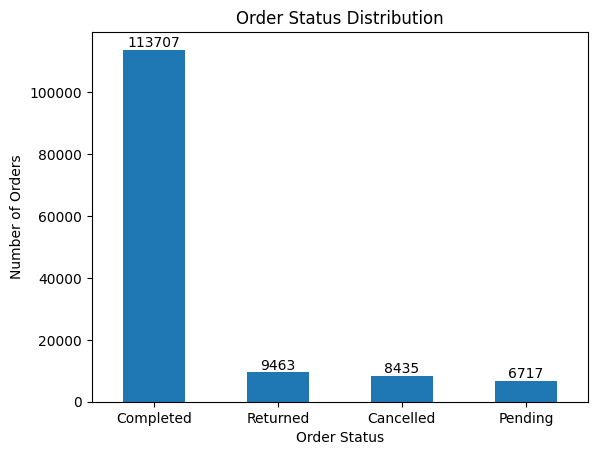

In [67]:
import matplotlib.pyplot as plt

# Count the number of orders in each order status category.
status_counts = df['order_status'].value_counts()

# Create a bar chart.
ax = status_counts.plot(kind='bar')

plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)

# Display the exact number of orders on top of each bar.
ax.bar_label(ax.containers[0])

plt.show()

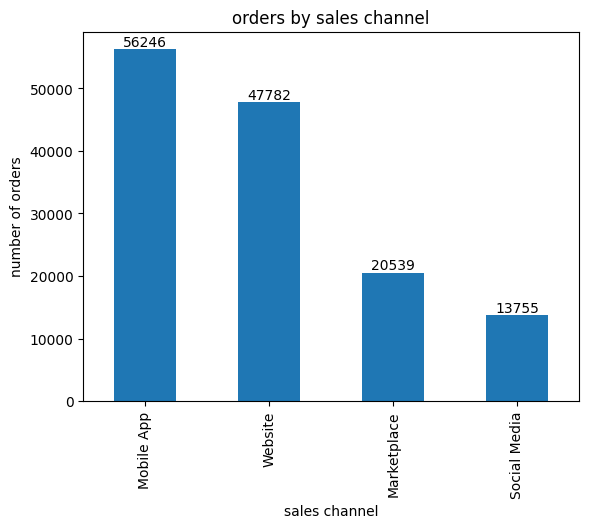

In [69]:
# Count orders for each sales channel.
channel_counts=df['sales_channel'].value_counts()
# Create a bar chart.
ax=channel_counts.plot(kind='bar')
plt.title("orders by sales channel")
plt.xlabel("sales channel")
plt.ylabel("number of orders")
# Show the exact number of orders on each bar.
ax.bar_label(ax.containers[0])
plt.show()

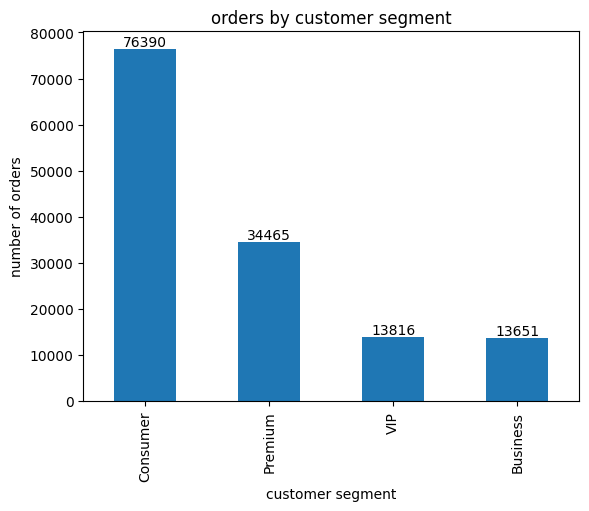

In [70]:
# Count orders for each customer segment.
segment_counts=df['customer_segment'].value_counts()
# Create a bar chart.
ax=segment_counts.plot(kind='bar')
plt.title("orders by customer segment")
plt.xlabel("customer segment")
plt.ylabel("number of orders")
# Show the exact number of orders on each bar.
ax.bar_label(ax.containers[0])
plt.show()

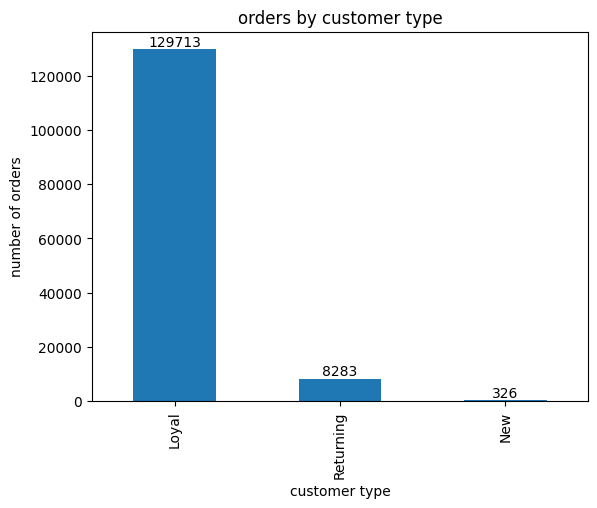

In [71]:
# Count orders for each customer type.
type_counts=df['customer_type'].value_counts()
# Create a bar chart.
ax=type_counts.plot(kind='bar')
plt.title("orders by customer type")
plt.xlabel("customer type")
plt.ylabel("number of orders")
# Show the exact number of orders on each bar.
ax=ax.bar_label(ax.containers[0])
plt.show()

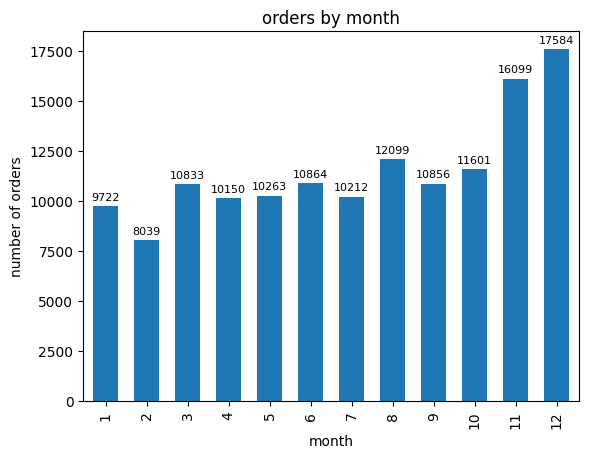

In [78]:
month_counts=df['order_month'].value_counts().sort_index()
ax=month_counts.plot(kind='bar',width=0.6)
plt.title("orders by month")
plt.xlabel("month")
plt.ylabel("number of orders")
ax.bar_label(ax.containers[0],fontsize=8, padding=3)
plt.show()

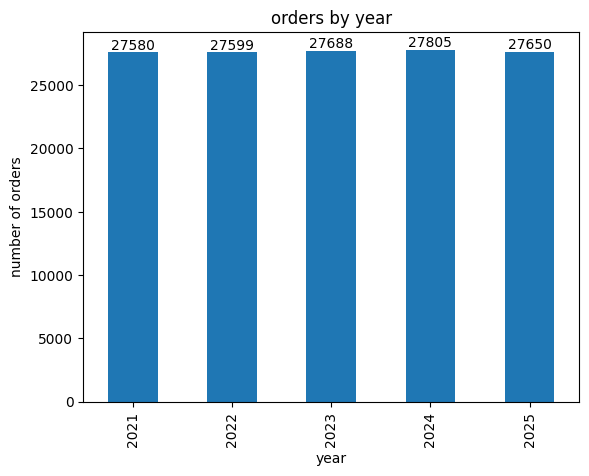

In [80]:
# Count the number of orders for each year.
year_counts=df['order_year'].value_counts().sort_index()
# Create a bar chart.
ax=year_counts.plot(kind='bar')
plt.title("orders by year")
plt.xlabel("year")
plt.ylabel("number of orders")
# Display the exact number of orders on each bar.
ax.bar_label(ax.containers[0])
plt.show()

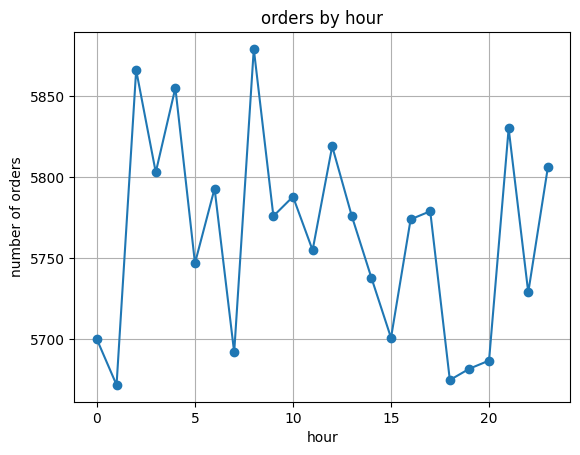

In [83]:
hour_counts=df['order_hour'].value_counts().sort_index()
ax=hour_counts.plot(kind="line",marker='o')
plt.title("orders by hour")
plt.xlabel("hour")
plt.ylabel("number of orders")
plt.grid(True)
plt.show()

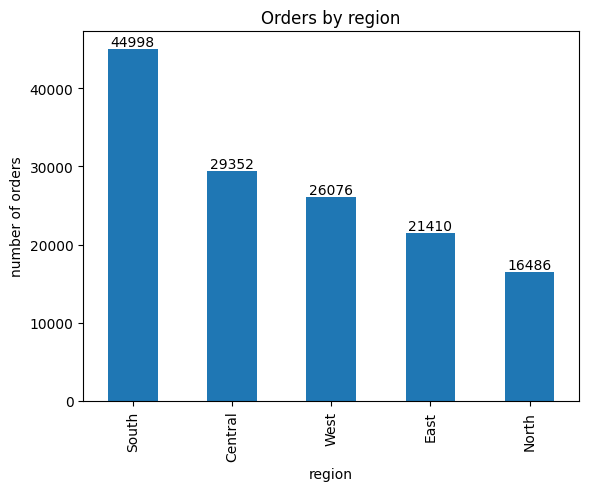

In [84]:
# Count the number of orders for each region.
region_counts=df['region'].value_counts()
# Create a bar chart.
ax=region_counts.plot(kind="bar")
plt.title("Orders by region")
plt.xlabel("region")
plt.ylabel("number of orders")
# Display the exact number of orders on each bar.
ax.bar_label(ax.containers[0])
plt.show()


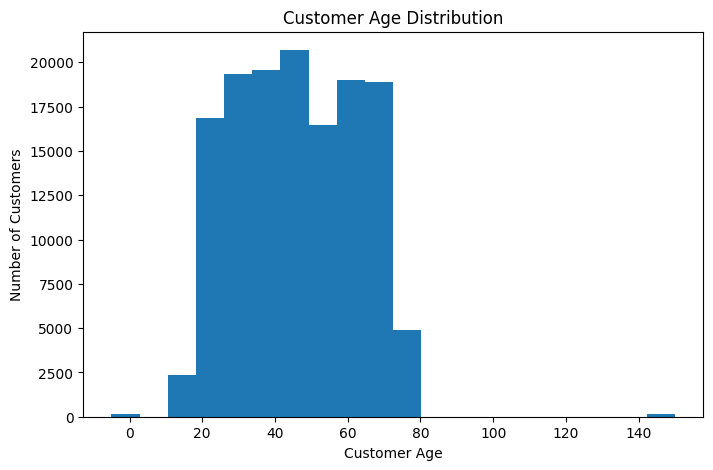

In [85]:
plt.figure(figsize=(8,5))
df['customer_age'].plot(kind="hist",bins=20)
plt.title("Customer Age Distribution")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")

plt.show()

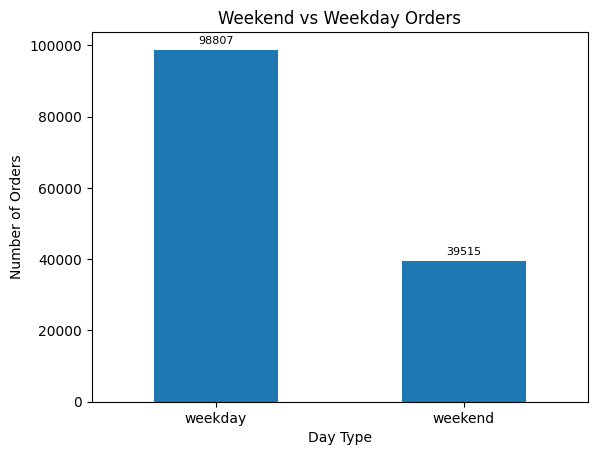

In [86]:
weekend_counts=df['is_weekend'].value_counts().sort_index()
weekend_counts.index=['weekday','weekend']
ax=weekend_counts.plot(kind='bar')
plt.title("Weekend vs Weekday Orders")
plt.xlabel("Day Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

ax.bar_label(ax.containers[0], fontsize=8, padding=3)

plt.show()

In [87]:
df.columns

Index(['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel',
       'customer_id', 'customer_name', 'customer_age', 'gender',
       'customer_segment', 'customer_type', 'customer_city', 'customer_state',
       'customer_country', 'region', 'order_year', 'order_month',
       'order_day_of_week', 'is_weekend', 'order_hour'],
      dtype='object')

In [88]:
# Define the target variable.
# The machine learning model will predict the order status.
target_column='order_status'
# Define columns that should not be used as model features.
# These columns are identifiers, personal information,or raw date/time columns from which useful features were already created.
columns_to_drop=[ 'order_id',
    'order_date',
    'order_time',
    'customer_id',
    'customer_name',
    'customer_city']
    # Remove the unnecessary columns from the dataset.
df_model=df.drop(columns=columns_to_drop)
# Display the remaining columns.
df_model.columns

Index(['order_status', 'sales_channel', 'customer_age', 'gender',
       'customer_segment', 'customer_type', 'customer_state',
       'customer_country', 'region', 'order_year', 'order_month',
       'order_day_of_week', 'is_weekend', 'order_hour'],
      dtype='object')

In [89]:
# Separate the target variable from the input features.
# The target variable is the value that the model will predict.
x=df_model.drop(columns=['order_status'])
# Store the target variable separately.
y=df_model['order_status']
# Display the shapes of X and y.
print("features shape:",x.shape)
print("target shape:",y.shape)

features shape: (138322, 13)
target shape: (138322,)


In [90]:
x.dtypes

,0
sales_channel,object
customer_age,float64
gender,object
customer_segment,object
customer_type,object
customer_state,object
customer_country,object
region,object
order_year,int32
order_month,int32


In [97]:
# Create a list of categorical columns that are currently available in X.
categorical_columns = [
    'sales_channel',
    'gender',
    'customer_segment',
    'customer_type',
    'customer_state',
    'customer_country',
    'region'
]
# Convert the selected categorical columns into numerical columns using one-hot encoding.
x_encoded=pd.get_dummies(
     # Provide the feature dataset that contains the categorical columns.
    x,
      # Specify the categorical columns that should be encoded.
    columns=categorical_columns,
      # Remove one category from each categorical column to avoid redundant information.
    drop_first=True,
     # Store the encoded values as integers, where 0 and 1 represent category membership.
    dtype=int
)
# Display the shape of the encoded feature dataset.
print("Encoded features shape:", x_encoded.shape)

Encoded features shape: (138322, 63)


In [98]:
# Display all feature column names created after one-hot encoding.
print(x_encoded.columns.tolist())

['customer_age', 'order_year', 'order_month', 'order_day_of_week', 'is_weekend', 'order_hour', 'sales_channel_Mobile App', 'sales_channel_Social Media', 'sales_channel_Website', 'gender_Male', 'gender_Non-Binary', 'customer_segment_Consumer', 'customer_segment_Premium', 'customer_segment_VIP', 'customer_type_New', 'customer_type_Returning', 'customer_state_Ajman', 'customer_state_Alberta', 'customer_state_Baden-Württemberg', 'customer_state_Bavaria', 'customer_state_British Columbia', 'customer_state_California', 'customer_state_Dubai', 'customer_state_England', 'customer_state_Florida', 'customer_state_Georgia', 'customer_state_Gujarat', 'customer_state_Hesse', 'customer_state_Illinois', 'customer_state_Karnataka', 'customer_state_Lower Saxony', 'customer_state_Maharashtra', 'customer_state_Manitoba', 'customer_state_Michigan', 'customer_state_New South Wales', 'customer_state_New York', 'customer_state_North Carolina', 'customer_state_North Rhine', 'customer_state_Northern Ireland', 

In [99]:
# Count the number of encoded features created for each original categorical column.
print("Sales Channel:", len([col for col in x_encoded.columns if col.startswith('sales_channel_')]))

# Count the number of encoded gender features.
print("Gender:", len([col for col in x_encoded.columns if col.startswith('gender_')]))

# Count the number of encoded customer segment features.
print("Customer Segment:", len([col for col in x_encoded.columns if col.startswith('customer_segment_')]))

# Count the number of encoded customer type features.
print("Customer Type:", len([col for col in x_encoded.columns if col.startswith('customer_type_')]))

# Count the number of encoded customer state features.
print("Customer State:", len([col for col in x_encoded.columns if col.startswith('customer_state_')]))

# Count the number of encoded customer country features.
print("Customer Country:", len([col for col in x_encoded.columns if col.startswith('customer_country_')]))

# Count the number of encoded region features.
print("Region:", len([col for col in x_encoded.columns if col.startswith('region_')]))

Sales Channel: 3
Gender: 2
Customer Segment: 3
Customer Type: 2
Customer State: 37
Customer Country: 6
Region: 4


In [100]:
# Import the train_test_split function from scikit-learn.
from sklearn.model_selection import train_test_split
# Split the encoded features and target variable into training and testing datasets.
x_train,x_test,y_train,y_test=train_test_split(
    # Provide the 63 encoded features as the input data.
    x_encoded,
    # Provide order_status as the target variable that we want to predict.
    y,
    # Reserve 20% of the data for testing and use 80% for training.
    test_size=0.20,
     # Keep the same proportion of Completed, Returned, Cancelled, and Pending classes in both training and testing datasets.
    stratify=y,
     # Set a fixed random seed so the same train-test split is created every time.
    random_state=57
)
# Display the number of rows and columns in the training feature dataset.
print("x_train shape:", x_train.shape)

# Display the number of rows and columns in the testing feature dataset.
print("x_test shape:", x_test.shape)

# Display the number of target values used for training.
print("y_train shape:", y_train.shape)

# Display the number of target values used for testing.
print("y_test shape:", y_test.shape)

x_train shape: (110657, 63)
x_test shape: (27665, 63)
y_train shape: (110657,)
y_test shape: (27665,)


In [103]:
# Import the Logistic Regression classification algorithm.
from sklearn.linear_model import LogisticRegression
# Create the Logistic Regression model.
logistic_model=LogisticRegression(
     # Allow the model more iterations to complete the training process.
    max_iter=2000,
     # Keep the results reproducible.
    random_state=57

)
# Train the model using the training features and training target.
logistic_model.fit(x_train,y_train)
# Predict the order status for the unseen test data.
y_pred_logistic=logistic_model.predict(x_test)
# Display the first 10 predictions.
print(y_pred_logistic[:10])

['Completed' 'Completed' 'Completed' 'Completed' 'Completed' 'Completed'
 'Completed' 'Completed' 'Completed' 'Completed']


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [104]:
# Import the accuracy score from scikit-learn.
from sklearn.metrics import accuracy_score
# Compare the predicted values with the actual test values.
accuracy=accuracy_score(y_test,y_pred_logistic)
# Display the model accuracy.
print("logistic regression accuracy",accuracy)

logistic regression accuracy 0.8220495210554852


In [105]:
# Import the classification report from scikit-learn.
from sklearn.metrics import classification_report
# Compare the predicted order statuses with the actual test values.
print(classification_report(y_test,y_pred_logistic))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

   Cancelled       0.00      0.00      0.00      1687
   Completed       0.82      1.00      0.90     22742
     Pending       0.00      0.00      0.00      1343
    Returned       0.00      0.00      0.00      1893

    accuracy                           0.82     27665
   macro avg       0.21      0.25      0.23     27665
weighted avg       0.68      0.82      0.74     27665



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [106]:
# Import the Decision Tree classification algorithm from scikit-learn.
from sklearn.tree import DecisionTreeClassifier
# Create the Decision Tree classification model.
decision_tree_model=DecisionTreeClassifier(
    # Set a fixed random seed to make the results reproducible.
    random_state=57

)
# Train the Decision Tree model using the training features and target values.
decision_tree_model.fit(x_train,y_train)
# Use the trained model to predict order statuses for the unseen test data.
y_pred_tree=decision_tree_model.predict(x_test)
# Display the first 10 predicted order statuses.
print(y_pred_tree[:10])

['Completed' 'Completed' 'Completed' 'Completed' 'Completed' 'Completed'
 'Returned' 'Completed' 'Completed' 'Completed']


In [107]:
# Import the accuracy score from scikit-learn.
from sklearn.metrics import accuracy_score
# Compare the Decision Tree predictions with the actual test values.
accuracy_tree=accuracy_score(y_test,y_pred_tree)
# Display the Decision Tree accuracy.
print("decision tree accuracy:",accuracy_tree)

decision tree accuracy: 0.6605096692571841


In [108]:
# Import the classification report from scikit-learn.
from sklearn.metrics import classification_report

# Compare the Decision Tree predictions with the actual test values.
print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

   Cancelled       0.07      0.08      0.07      1687
   Completed       0.82      0.79      0.80     22742
     Pending       0.05      0.06      0.06      1343
    Returned       0.08      0.10      0.09      1893

    accuracy                           0.66     27665
   macro avg       0.26      0.26      0.26     27665
weighted avg       0.69      0.66      0.67     27665



In [110]:
# Import the Random Forest classification algorithm from scikit-learn.
from sklearn.ensemble import RandomForestClassifier
# Create the Random Forest classification model.
random_forest_model=RandomForestClassifier(
    n_estimators=1000,
    random_state=57,
    n_jobs=-1
)
# Train the Random Forest model using the training features and target values.
random_forest_model.fit(x_train,y_train)
# Use the trained model to predict order statuses for the unseen test data.
y_pred_rf=random_forest_model.predict(x_test)
# Display the first 10 predicted order statuses.
print(y_pred_rf[:10])

['Completed' 'Completed' 'Completed' 'Completed' 'Completed' 'Completed'
 'Completed' 'Completed' 'Completed' 'Completed']


In [111]:
# Import evaluation metrics from scikit-learn.
from sklearn.metrics import accuracy_score,classification_report
# Calculate the accuracy of the Random Forest model.
rf_accuracy=accuracy_score(y_test,y_pred_rf)
# Display the Random Forest accuracy.
print("random forest accuracy",rf_accuracy)
# Display precision, recall, and F1-score for each order status.
print("random forest classification report")
print(classification_report(y_test,y_pred_rf))

random forest accuracy 0.8221218145671426
random forest classification report
              precision    recall  f1-score   support

   Cancelled       0.36      0.00      0.01      1687
   Completed       0.82      1.00      0.90     22742
     Pending       0.58      0.01      0.02      1343
    Returned       0.48      0.01      0.01      1893

    accuracy                           0.82     27665
   macro avg       0.56      0.25      0.23     27665
weighted avg       0.76      0.82      0.74     27665



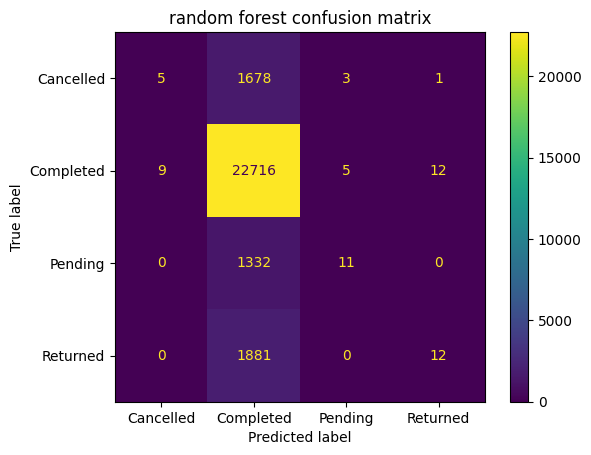

In [112]:
# Import the confusion matrix function and display class from scikit-learn.
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
# Calculate the confusion matrix using the actual and predicted values.
cm=confusion_matrix(y_test,y_pred_rf)
# Create a visual display of the confusion matrix.
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Cancelled', 'Completed', 'Pending', 'Returned'])
# Plot the confusion matrix.
disp.plot()
# Add a title to the chart.
plt.title("random forest confusion matrix")
# Display the chart.
plt.show()

In [114]:
# Import the Random Forest classification algorithm.
from sklearn.ensemble import RandomForestClassifier
# Create a Random Forest model with balanced class weights.
# The balanced option gives more importance to minority classes.
balanced_rf_model=RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=57,
    n_jobs=-1
)
# Train the balanced Random Forest model using the training data.
balanced_rf_model.fit(x_train,y_train)
# Predict order statuses for the unseen test data.
y_pred_balanced_rf=balanced_rf_model.predict(x_test)
# Display the first 10 predictions.
print(y_pred_balanced_rf[:10])

['Completed' 'Completed' 'Completed' 'Completed' 'Completed' 'Completed'
 'Completed' 'Completed' 'Completed' 'Completed']


In [115]:
# Import evaluation metrics from scikit-learn.
from sklearn.metrics import accuracy_score, classification_report

# Calculate the accuracy of the balanced Random Forest model.
balanced_rf_accuracy = accuracy_score(y_test, y_pred_balanced_rf)

# Display the accuracy.
print("Balanced Random Forest Accuracy:", balanced_rf_accuracy)

# Display precision, recall, and F1-score for each order status.
print("Balanced Random Forest Classification Report:")
print(classification_report(y_test, y_pred_balanced_rf))

Balanced Random Forest Accuracy: 0.8216157599855413
Balanced Random Forest Classification Report:
              precision    recall  f1-score   support

   Cancelled       0.24      0.00      0.01      1687
   Completed       0.82      1.00      0.90     22742
     Pending       0.55      0.01      0.02      1343
    Returned       0.36      0.01      0.01      1893

    accuracy                           0.82     27665
   macro avg       0.49      0.25      0.23     27665
weighted avg       0.74      0.82      0.74     27665



In [120]:
# Create a DataFrame containing each feature and its importance score.
feature_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': decision_tree_model.feature_importances_
})

# Sort the features from highest importance to lowest importance.
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display the top 10 most important features.
print(feature_importance.head(10))

                      Feature  Importance
0                customer_age    0.180159
5                  order_hour    0.151282
2                 order_month    0.121638
3           order_day_of_week    0.098449
1                  order_year    0.050443
9                 gender_Male    0.039611
11  customer_segment_Consumer    0.031376
12   customer_segment_Premium    0.023769
8       sales_channel_Website    0.022483
13       customer_segment_VIP    0.016329


In [121]:
# Import pandas for creating the model comparison table.
import pandas as pd

# Create a comparison table for all trained models.
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'Balanced Random Forest'
    ],
    'Accuracy': [
        0.8220495210554852,
        0.6605096692571841,
        0.8221218145671426,
        0.8216157599855413
    ],
    'Macro F1': [
        0.23,
        0.26,
        0.23,
        0.23
    ]
})

# Display the model comparison table.
print(model_comparison)

                    Model  Accuracy  Macro F1
0     Logistic Regression  0.822050      0.23
1           Decision Tree  0.660510      0.26
2           Random Forest  0.822122      0.23
3  Balanced Random Forest  0.821616      0.23
